# Geometry changes the inference problem

Non-centering is an invertible coordinate transformation, not a change to the original target. Both protocols are visualized and diagnosed in the same original coordinates.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
ROOT=Path.cwd()
if ROOT.name == "notebooks": ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
torch.set_num_threads(1)
from sampling_lab.targets import load_target
from sampling_lab.artifacts import sha256
def read(path): return json.loads((ROOT/path).read_text())
def numeric(name): return np.load(ROOT/"assets/source_data"/(name+".npz"),allow_pickle=False)
%matplotlib inline


## Independent implementation check

In [2]:
noncentered=numeric("funnel_noncentered_nuts_dispersed_0.1")
raw=noncentered["samples"];observed=noncentered["observables"]
np.testing.assert_array_equal(observed[:,:,1],raw[:,:,1]*np.exp(raw[:,:,0]/2))
np.testing.assert_array_equal(observed[:,:,0],raw[:,:,0])
rows=pd.read_csv(ROOT/"docs/sampling_comparison.csv")
display(rows[rows.target.isin(["funnel","funnel_noncentered"])&rows.method.isin(["hmc","adaptive_hmc","nuts"])][["target","method","max_rhat","min_bulk_ess","divergences","convergence_flag"]])

,target,method,max_rhat,min_bulk_ess,divergences,convergence_flag
8,funnel,adaptive_hmc,1.015651,293.570972,485,False
10,funnel,hmc,2.196321,5.833835,4003,False
12,funnel_noncentered,adaptive_hmc,1.001131,5786.709265,0,True
14,funnel_noncentered,hmc,1.021785,314.457151,0,False
16,funnel_noncentered,nuts,1.000735,5481.282499,0,True
20,funnel,nuts,1.121126,25.202184,577,False


## Inspect measured evidence

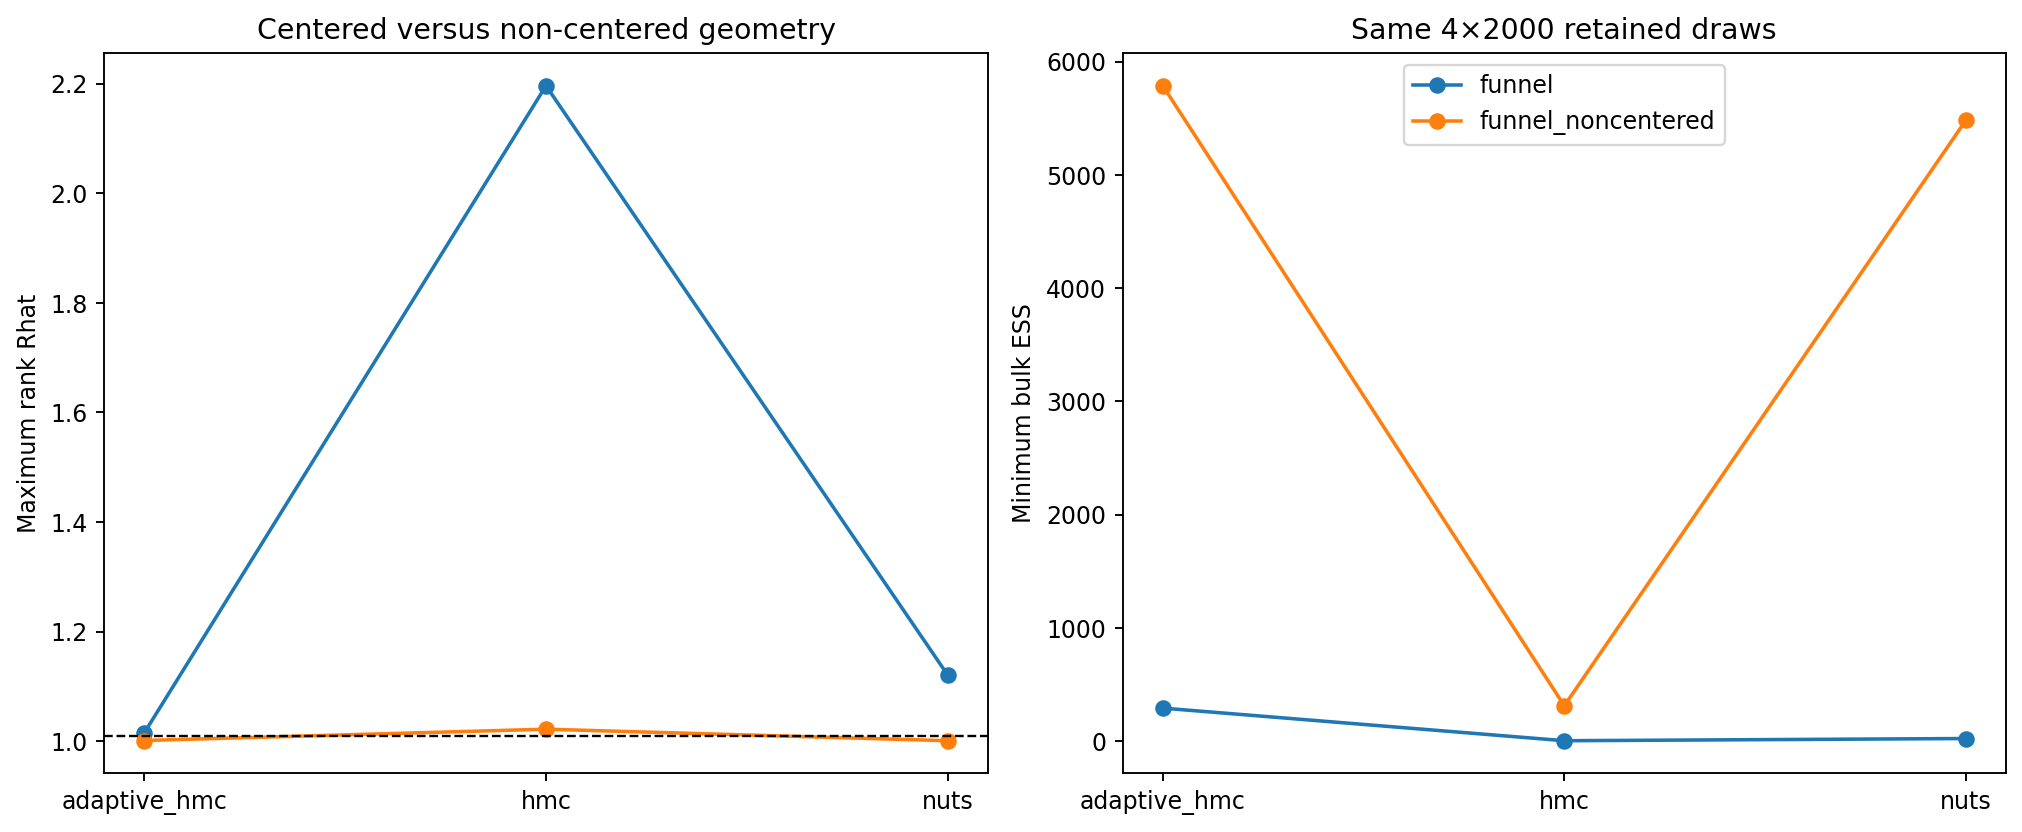

The exact reference draws still have Monte Carlo moment error, especially in heavy funnel tails.


In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT/"assets/figures/funnel_geometry.png")))
print("The exact reference draws still have Monte Carlo moment error, especially in heavy funnel tails.")

## Interpretation and next step

Read the [theory](../docs/theory.md), [diagnostic scope](../docs/diagnostics.md), and [data protocol](../docs/data_and_protocols.md). Change one declared preset in a separate output directory; keep warmup, test evaluation and model selection distinct. The [interactive explorer](../docs/explorer.html) exposes the complete recorded comparisons.